# 01 — Signal maps and diagnostics
Signals from `signals.py` (GPU job), scores from `diagnostics.py`. **All mIoU numbers are 5-fold CV on train,
held-out folds only, official `miou_image`.**

Extractor check (run on GPU before the step; numbers printed by the check script):

| extractor | map before pooling | head after pooling | agreement map |
|---|---|---|---|
| PixelSeal | 768×8×8 (input resized to 256) | mean pool → Linear(768→257) | exact (mean of per-position logits = logits, err 2e-6) |
| TrustMark | layer4 2048×8×8 (input 245) | avg pool → Linear(2048→100) | exact (err 9e-8) |
| StegaStamp | 7 convs | flatten → Dense → ReLU → Dense | **none** (nonlinear head) |

Signals: `resid` log residual energy · `agree` exact agreement map · `win64/128/256` sliding-window decoding
agreement with crops of that size · `winmean` their mean · `_z` = standardised within each image.

In [1]:
import sys; sys.path.insert(0, '..')
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import data
pd.set_option('display.width', 160); pd.set_option('display.max_rows', 100)
df = data.train_table().set_index('name'); gts = data.train_masks128()
ds = data.load_split('train'); idx = {m['image_name']: i for i, m in enumerate(ds.meta)}
diag = pd.read_csv(data.RESULTS / 'step1_diag.csv')
sig = {m: np.load(data.RESULTS / 'signals' / f'{m}_train.npz') for m in data.METHODS}
cv = {m: np.load(data.RESULTS / f'step1_cv_{m}.npz') for m in data.METHODS}

## 1. Diagnostic table
`auc`: cell-level AUC over all train cells (0.5 = useless; < 0.5 means *low* signal = watermarked, the
predictors flip it). `cv_thr`: one threshold. `cv_regime`: full/partial gate, then one threshold per regime.
Reference: constant all-0 = 0.252, perfect regime + constant = 0.455.

In [2]:
for m in data.METHODS:
    t = diag[diag.method == m].set_index('signal')[['auc', 'cv_thr', 'cv_regime', 'cv_regime_full', 'cv_regime_partial']]
    print('=' * 20, m); display(t.sort_values('cv_regime', ascending=False).style.format('{:.3f}').highlight_max(axis=0, subset=['cv_thr', 'cv_regime']))

==================== pixelseal


,auc,cv_thr,cv_regime,cv_regime_full,cv_regime_partial
signal,,,,,
agree_z,0.543,0.324,0.470,0.456,0.484
winmean,0.873,0.462,0.469,0.448,0.491
winmean_z,0.547,0.312,0.469,0.449,0.489
agree,0.944,0.458,0.462,0.462,0.461
win256,0.873,0.452,0.459,0.448,0.470
win128,0.513,0.290,0.456,0.452,0.461
win128_z,0.505,0.283,0.453,0.451,0.456
win64,0.508,0.281,0.452,0.447,0.457
win64_z,0.500,0.279,0.451,0.448,0.455


==================== trustmark


,auc,cv_thr,cv_regime,cv_regime_full,cv_regime_partial
signal,,,,,
winmean,0.526,0.282,0.465,0.450,0.480
agree,0.912,0.464,0.464,0.462,0.467
winmean_z,0.511,0.282,0.463,0.448,0.478
win128_z,0.502,0.279,0.461,0.450,0.472
win128,0.520,0.281,0.460,0.449,0.470
resid_z,0.509,0.287,0.454,0.451,0.458
win256,0.515,0.289,0.453,0.449,0.458
agree_z,0.547,0.314,0.453,0.452,0.455
win64_z,0.503,0.277,0.452,0.451,0.454


==================== stegastamp


,auc,cv_thr,cv_regime,cv_regime_full,cv_regime_partial
signal,,,,,
resid,0.608,0.341,0.485,0.506,0.465
resid_z,0.549,0.306,0.477,0.489,0.466
win128_z,0.496,0.277,0.459,0.460,0.457
win64_z,0.500,0.274,0.458,0.457,0.459
win128,0.501,0.272,0.457,0.455,0.459
winmean,0.503,0.268,0.457,0.455,0.459
win64,0.497,0.275,0.457,0.455,0.459
win256,0.509,0.277,0.456,0.454,0.459
win256_z,0.496,0.275,0.456,0.454,0.459


## 2. Full vs partial from the whole-image agreement

,cv_accuracy,acc_full,acc_partial,auc_global_soft
method,,,,
pixelseal,0.971,1.000,0.941,0.998
trustmark,0.971,0.976,0.965,0.999
stegastamp,0.976,0.988,0.965,0.999


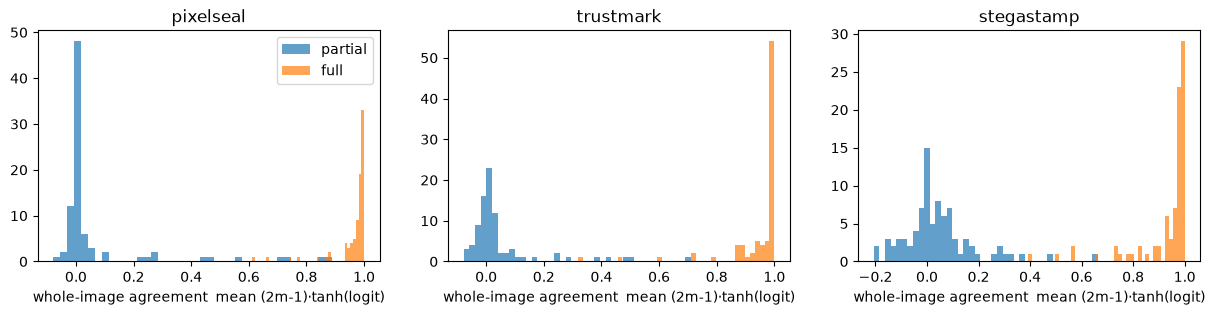

In [3]:
display(pd.read_csv(data.RESULTS / 'step1_regime.csv').set_index('method').round(3))
fig, axs = plt.subplots(1, 3, figsize=(15, 3))
for ax, m in zip(axs, data.METHODS):
    f = df.loc[sig[m]['names'].tolist()].full_watermark.values; g = sig[m]['global_soft']
    ax.hist(g[~f], bins=40, alpha=.7, label='partial'); ax.hist(g[f], bins=40, alpha=.7, label='full')
    ax.set_title(m); ax.set_xlabel('whole-image agreement  mean (2m-1)·tanh(logit)')
axs[0].legend(); plt.show()

## 3. Maps side by side
For each method: 3 *full* and 3 *partial* random images. Columns: image · ground truth (white = watermarked) ·
each signal map · held-out prediction of the best predictor. Maps use their own colour scale (bright = high).

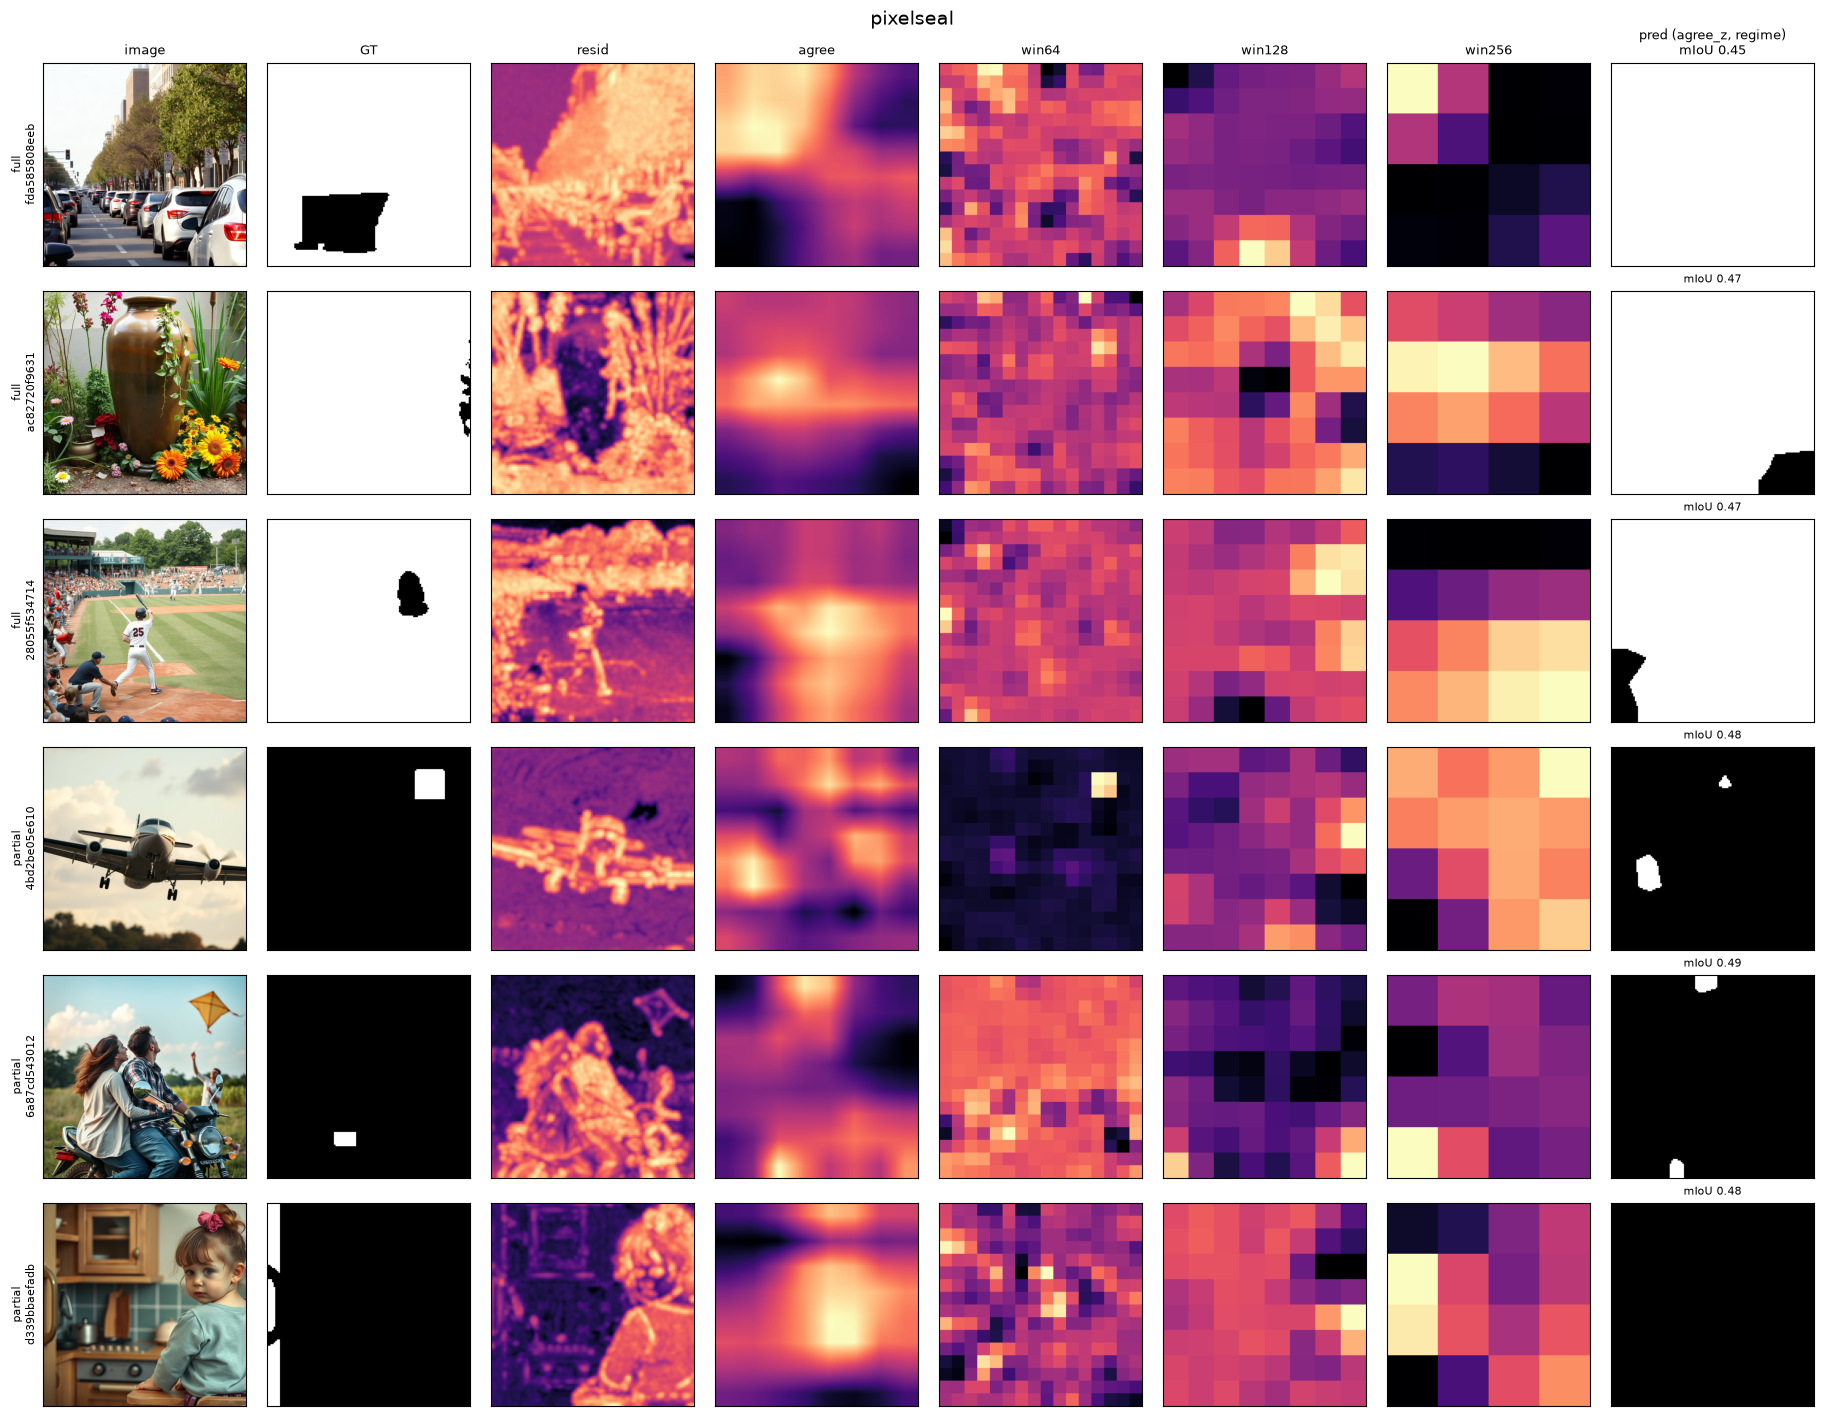

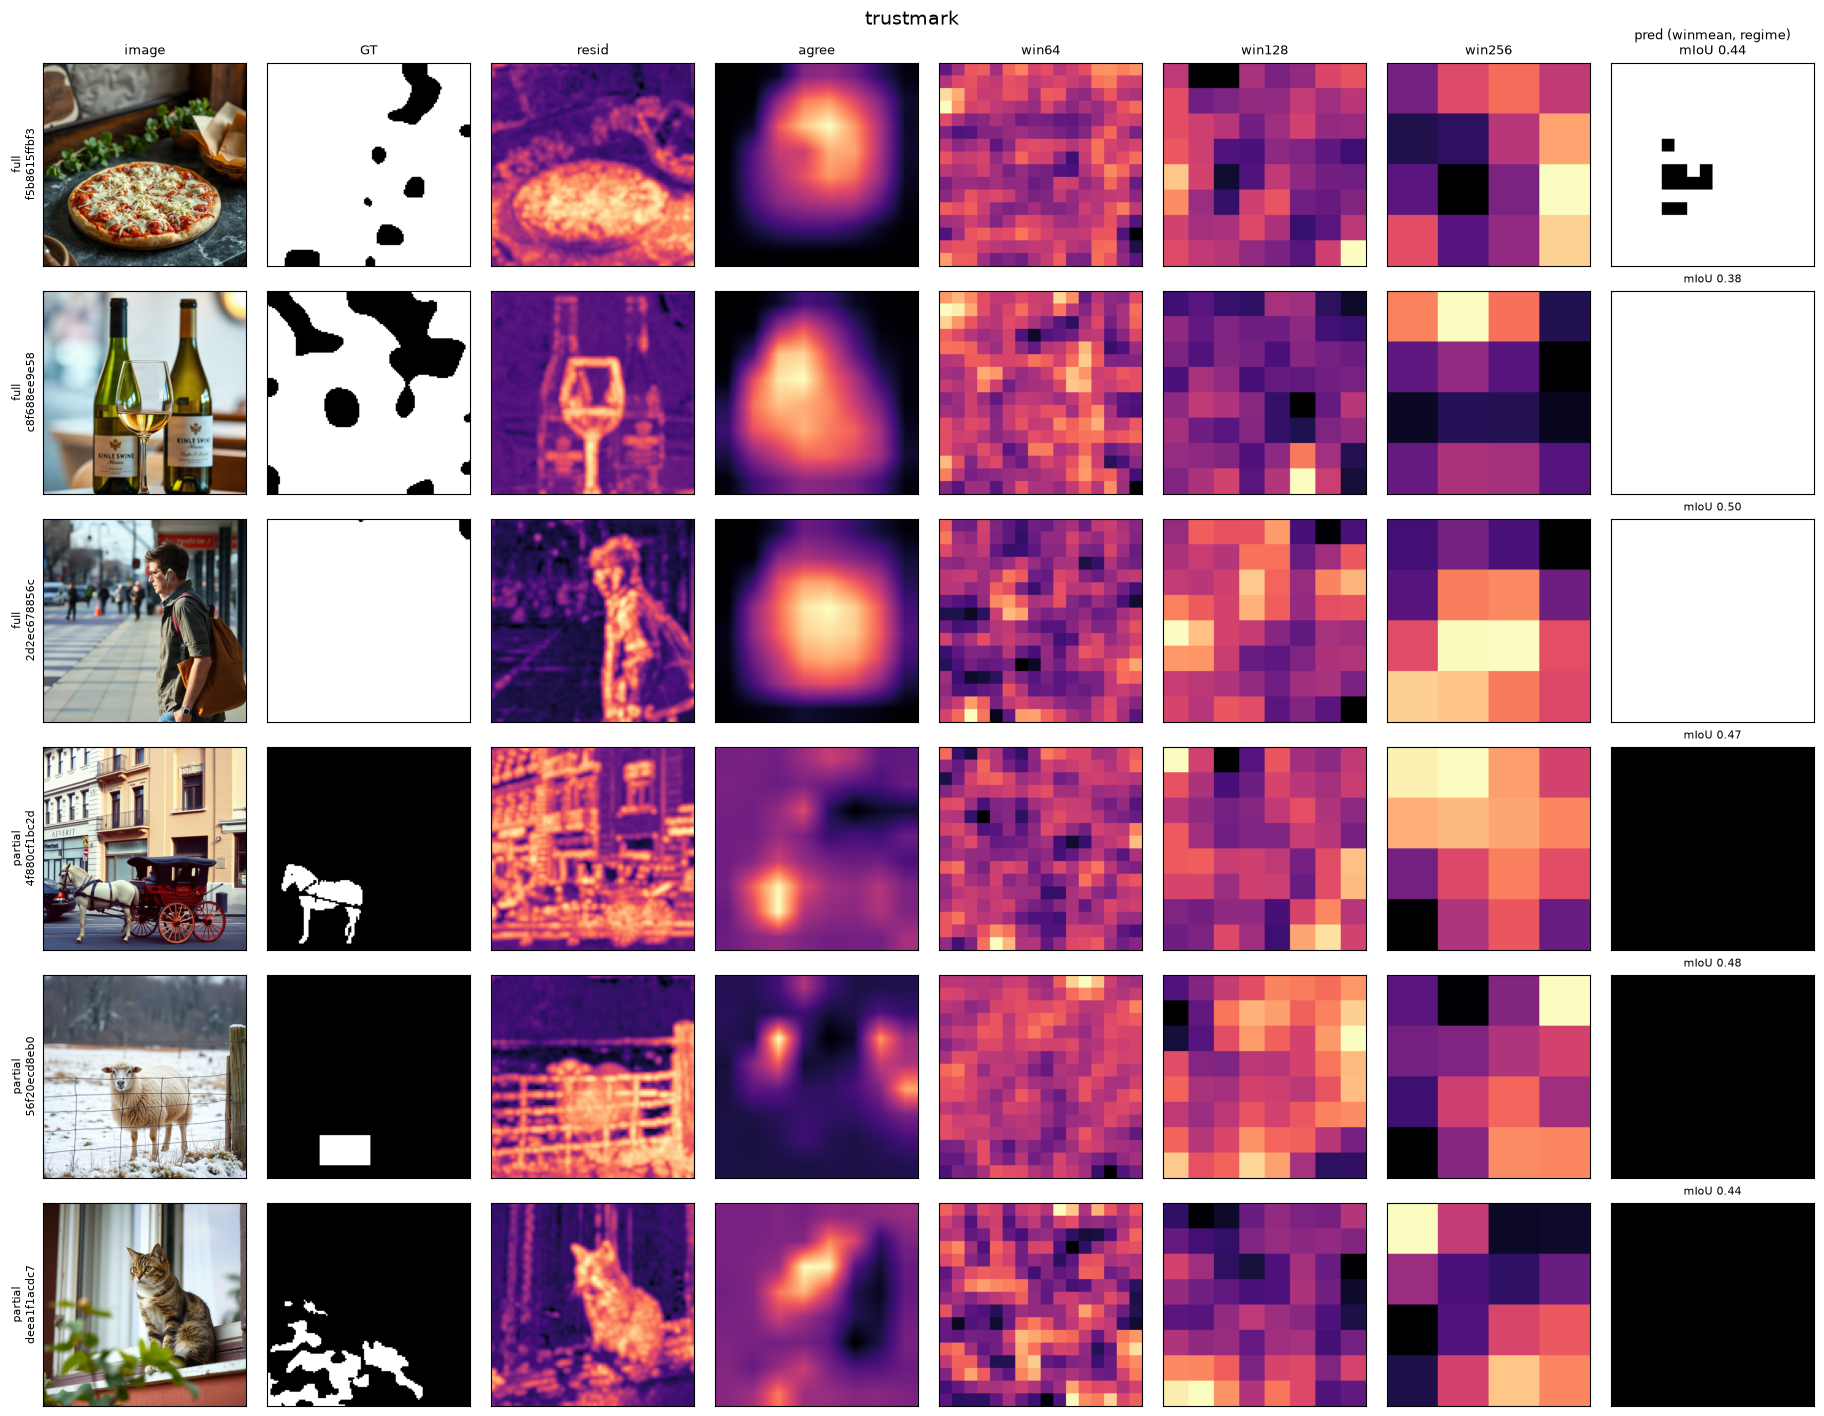

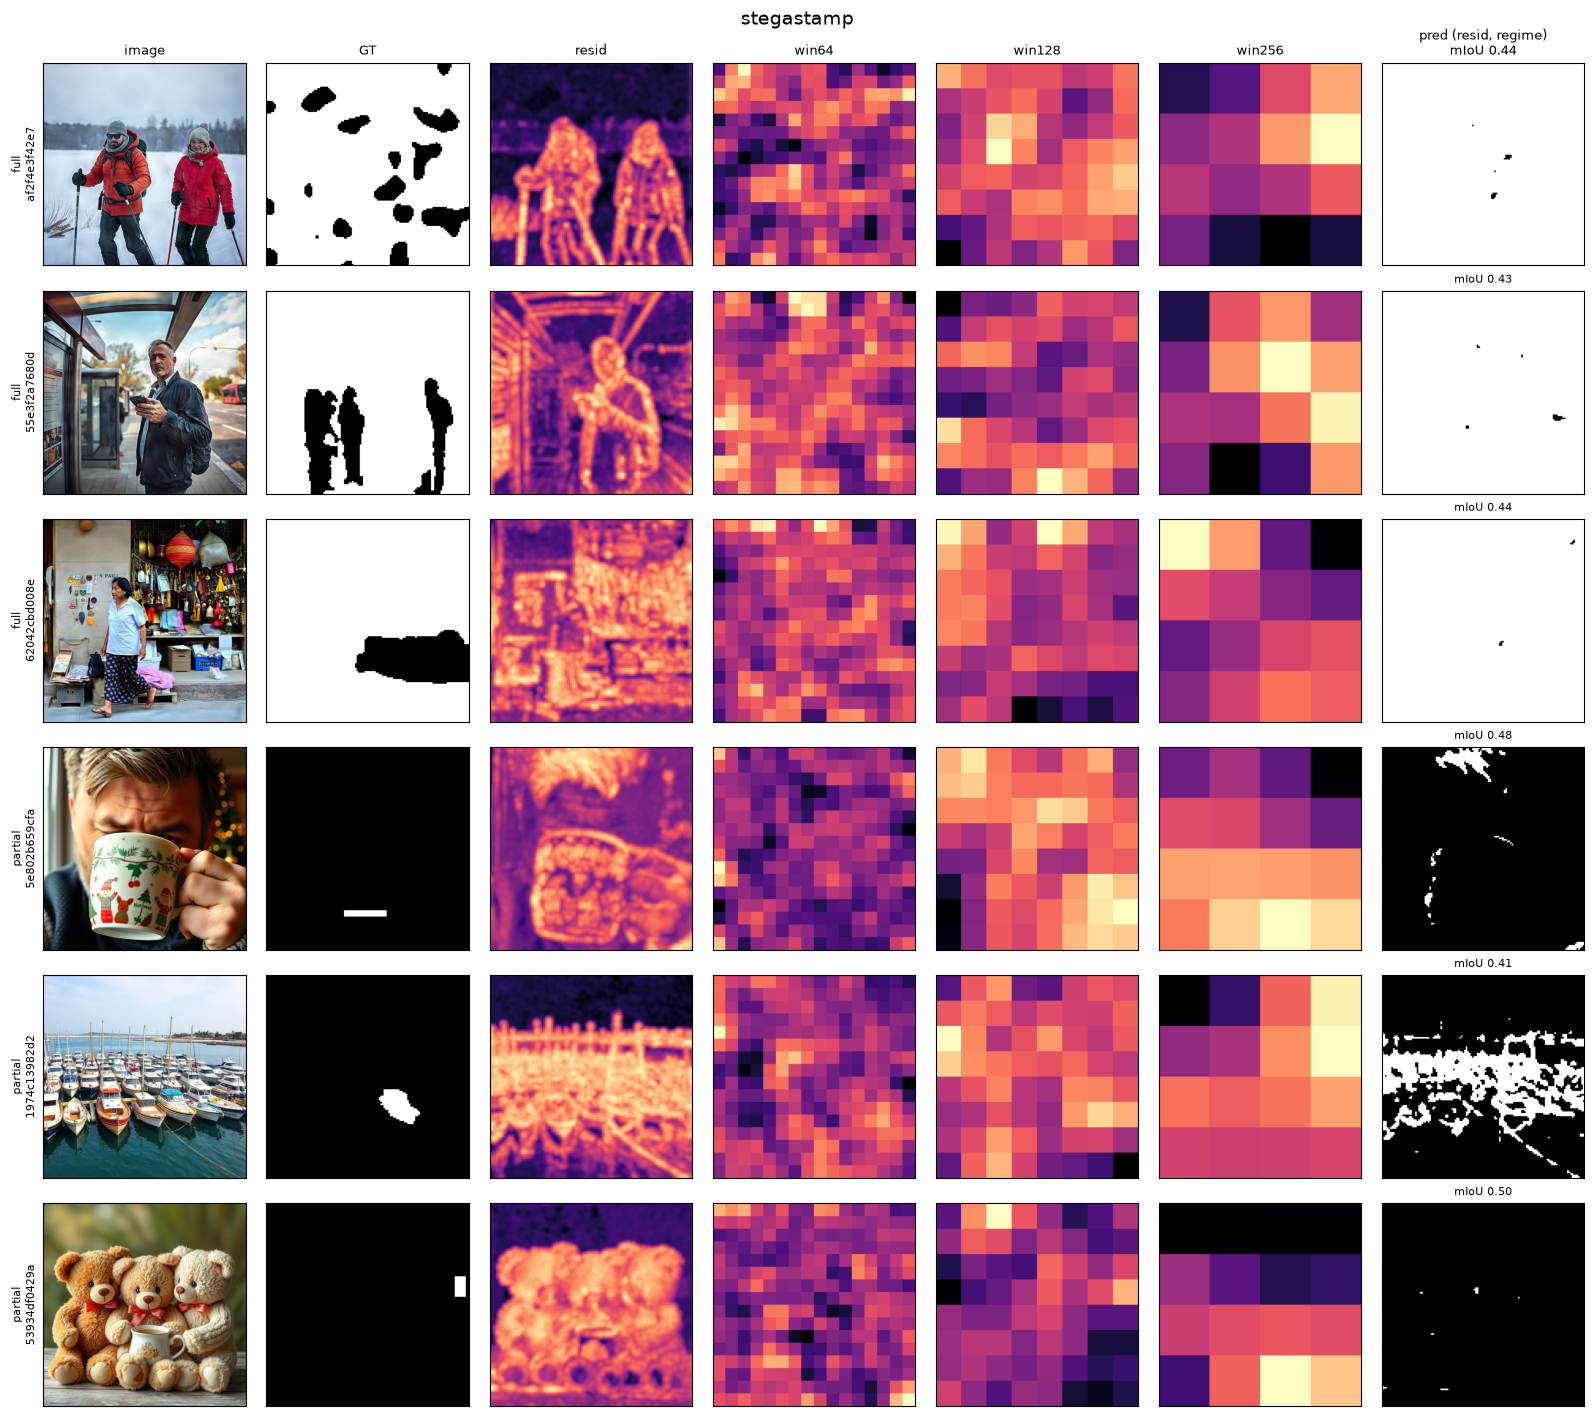

In [4]:
def panel(m, names):
    z = sig[m]; pos = {n: i for i, n in enumerate(z['names'].tolist())}
    keys = [k for k in ['resid', 'agree', 'win64', 'win128', 'win256'] if k in z.files]
    c = cv[m]; cpos = {n: i for i, n in enumerate(c['names'].tolist())}
    cols = 3 + len(keys)
    fig, axs = plt.subplots(len(names), cols, figsize=(2.3 * cols, 2.4 * len(names)))
    for r, n in enumerate(names):
        i = pos[n]
        axs[r, 0].imshow(ds[idx[n]]['image']); axs[r, 0].set_ylabel(f"{df.loc[n].regime}\n{n}", fontsize=8)
        axs[r, 1].imshow(gts[n], cmap='gray', vmin=0, vmax=1)
        for j, k in enumerate(keys):
            axs[r, 2 + j].imshow(z[k][i].astype(float), cmap='magma')
        axs[r, -1].imshow(c['pred'][cpos[n]], cmap='gray', vmin=0, vmax=1)
        axs[r, -1].set_title(f"mIoU {c['miou'][cpos[n]]:.2f}", fontsize=8)
        for a in axs[r]: a.set_xticks([]); a.set_yticks([])
    for a, t in zip(axs[0], ['image', 'GT'] + keys + [f"pred ({c['signal']}, {c['variant']})"]):
        a.set_title(t + ('' if a is not axs[0, -1] else f"\nmIoU {c['miou'][cpos[names[0]]]:.2f}"), fontsize=9)
    fig.suptitle(m, fontsize=14); plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
for m in data.METHODS:
    t = df.loc[sig[m]['names'].tolist()]
    names = list(rng.choice(t[t.full_watermark].index, 3, replace=False)) + list(rng.choice(t[~t.full_watermark].index, 3, replace=False))
    panel(m, names)

## 4. Best and worst held-out images of the best predictor

pixelseal best predictor: agree_z regime  mean held-out mIoU 0.4696


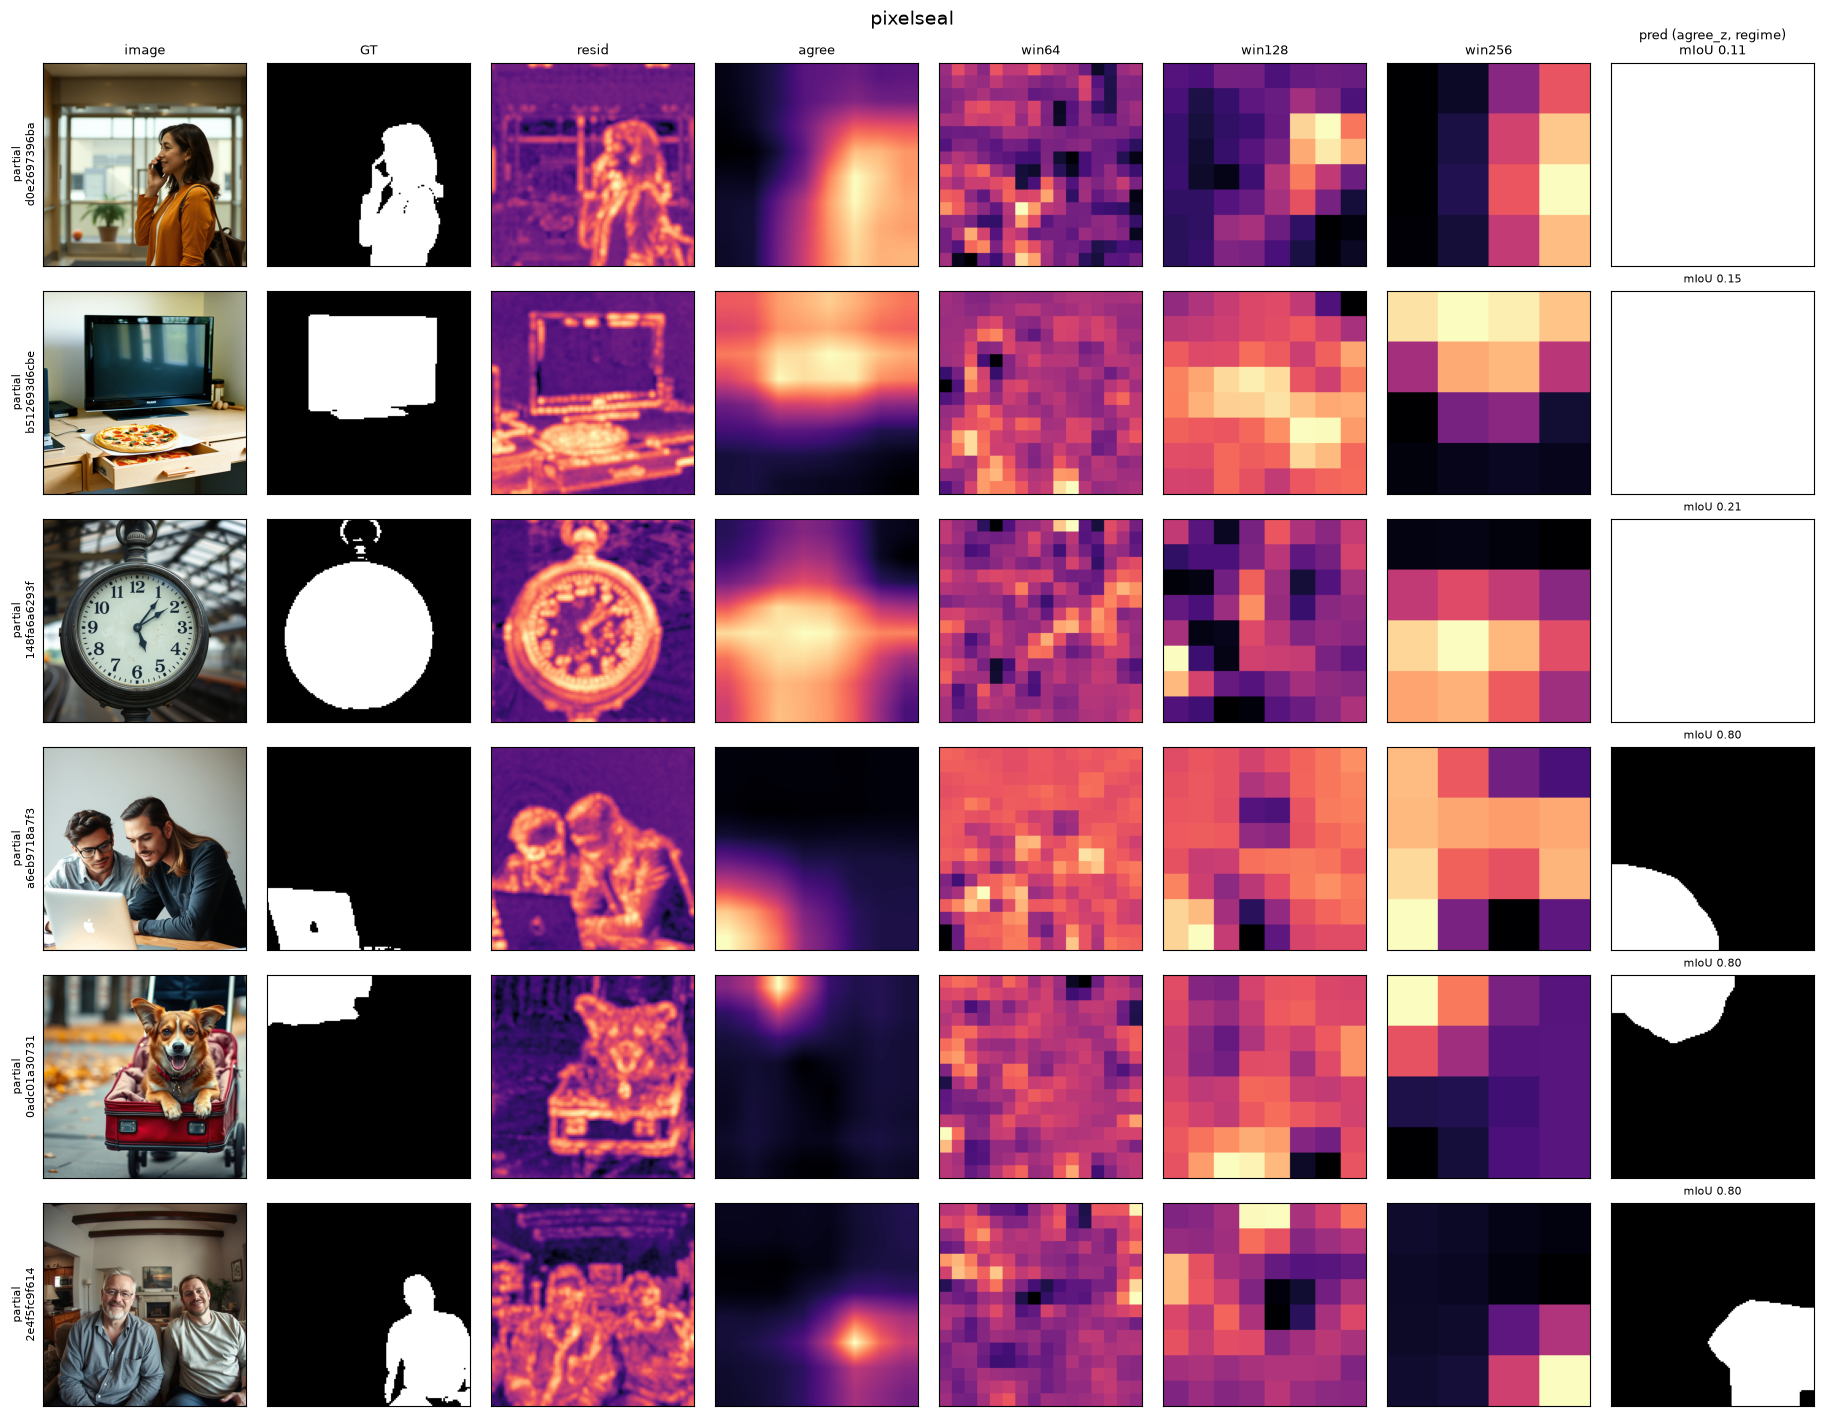

trustmark best predictor: winmean regime  mean held-out mIoU 0.465


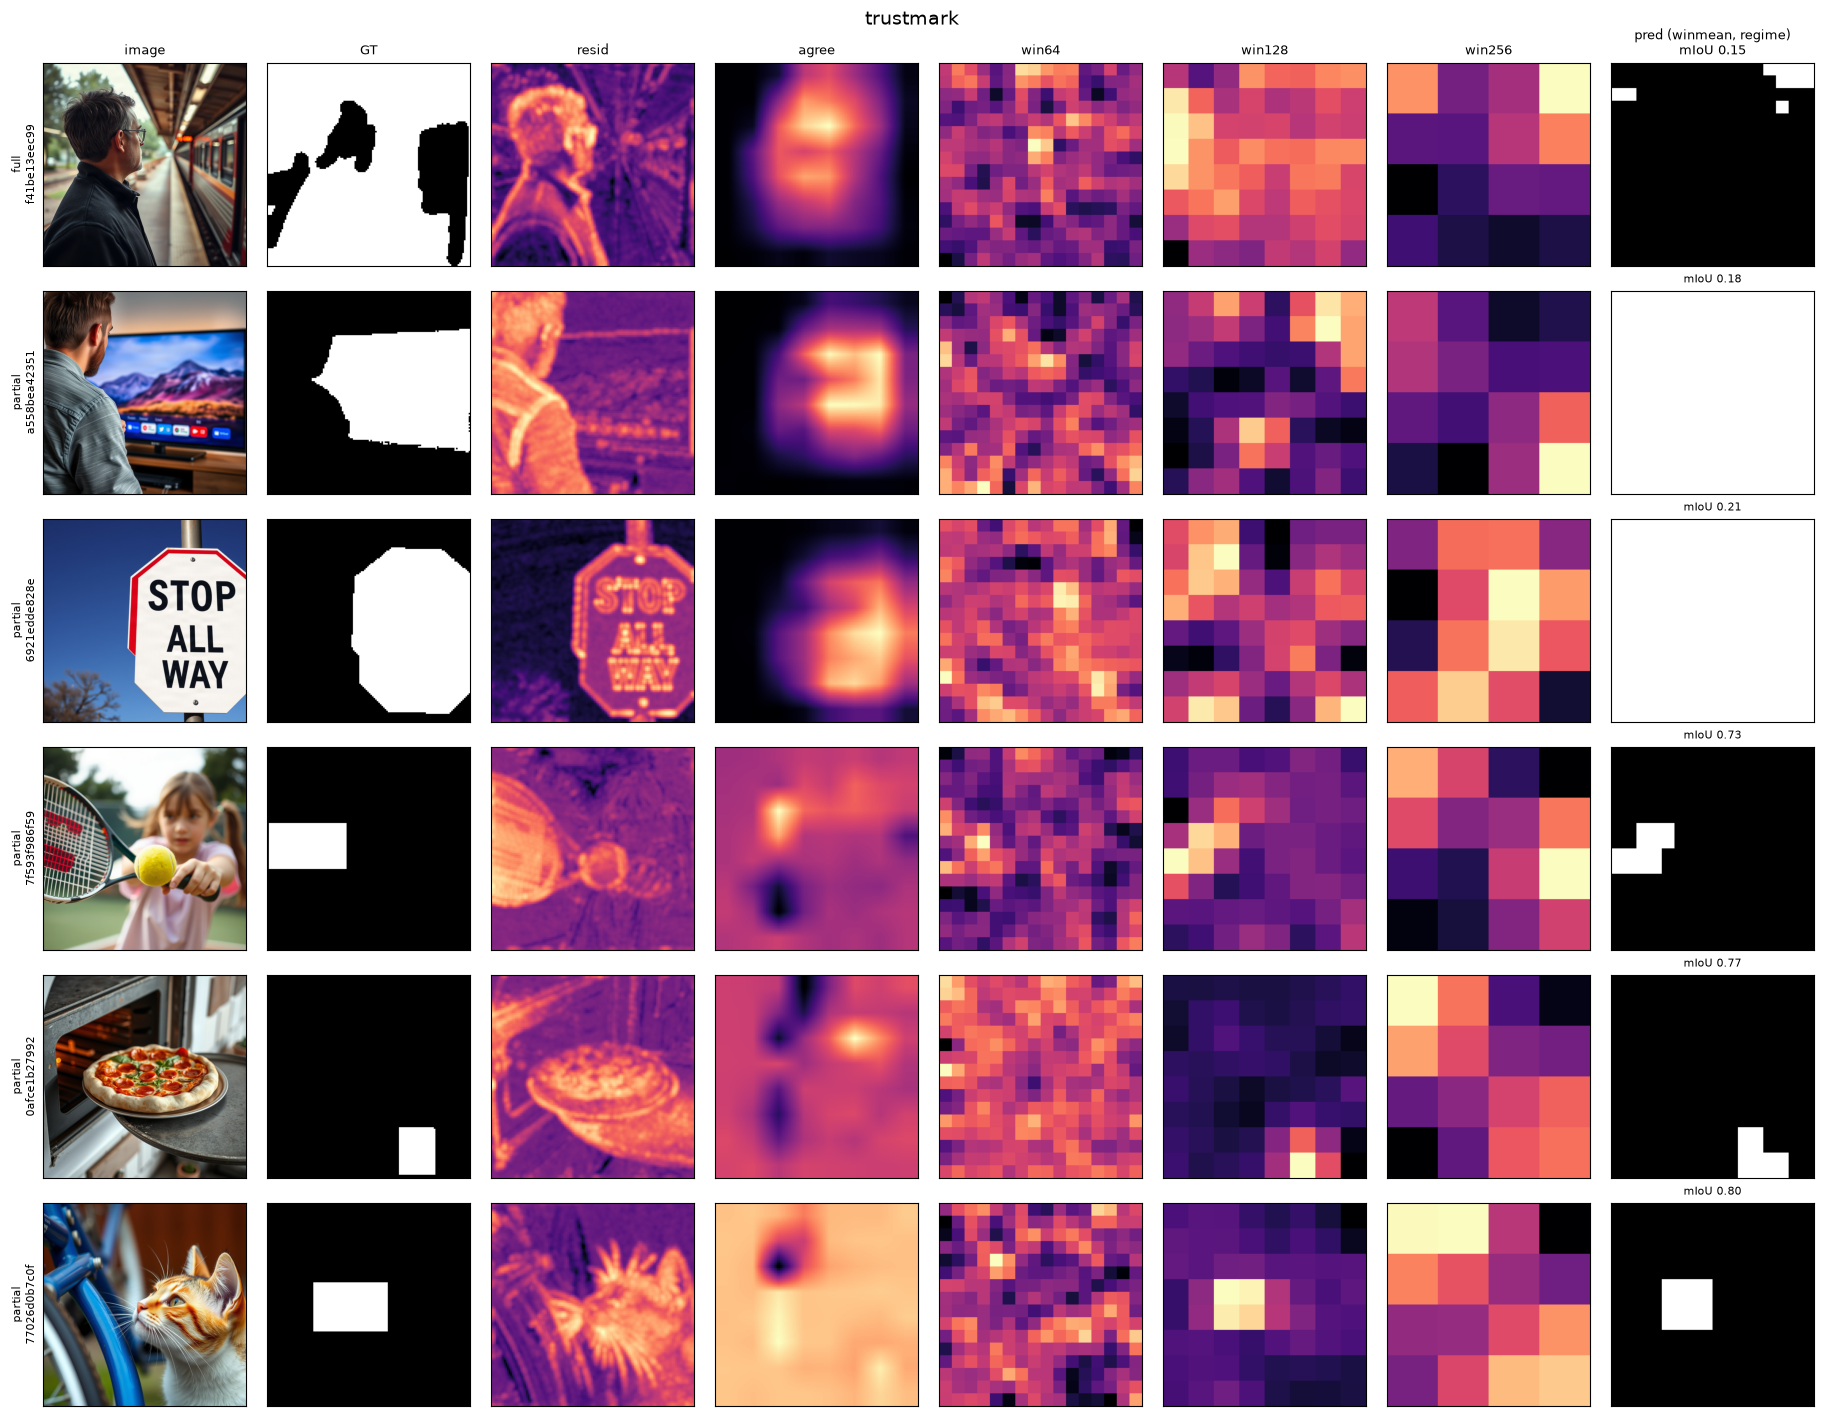

stegastamp best predictor: resid regime  mean held-out mIoU 0.4852


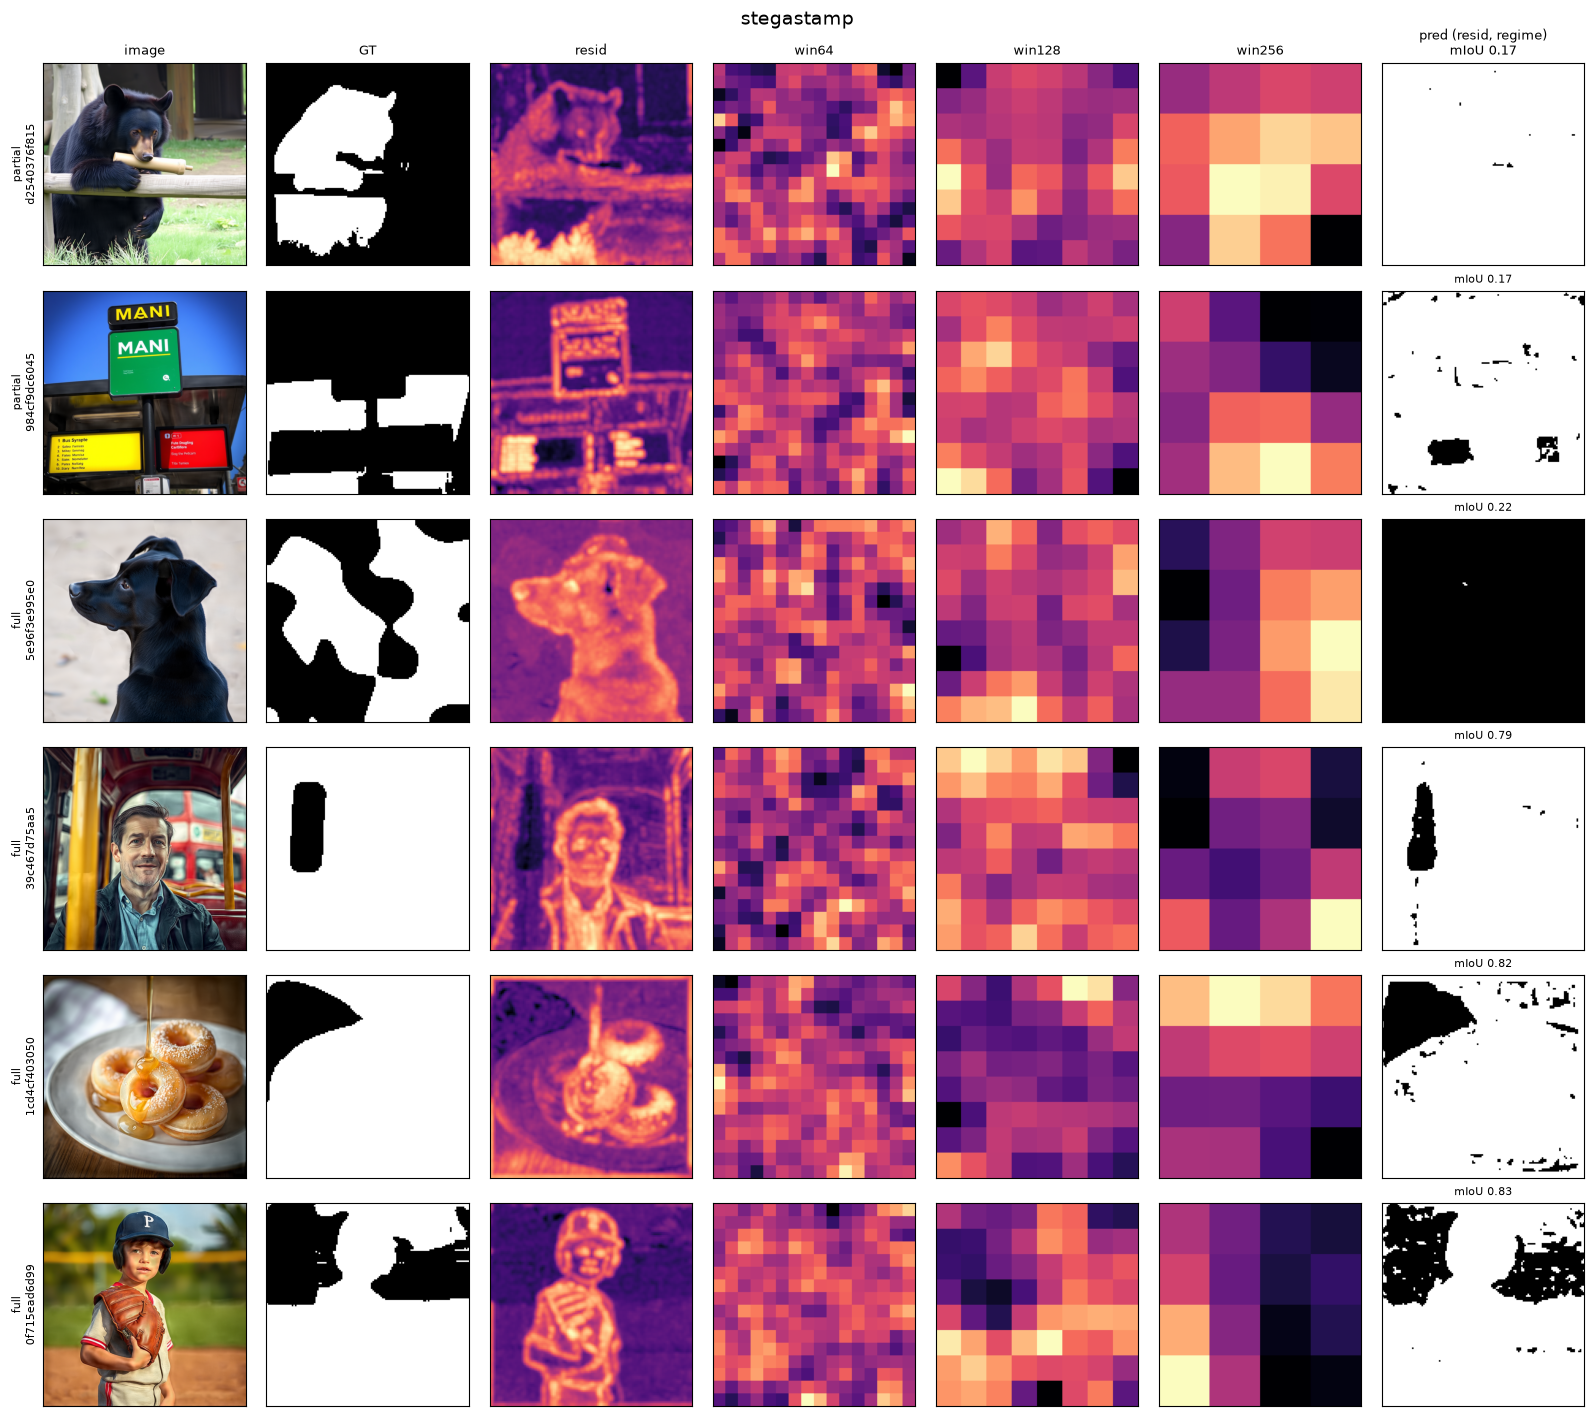

In [5]:
for m in data.METHODS:
    c = cv[m]; order = np.argsort(c['miou']); nm = c['names']
    print(m, 'best predictor:', str(c['signal']), str(c['variant']), ' mean held-out mIoU', c['miou'].mean().round(4))
    panel(m, [nm[i] for i in order[:3]] + [nm[i] for i in order[-3:]])

## 5. Distribution of per-image held-out mIoU

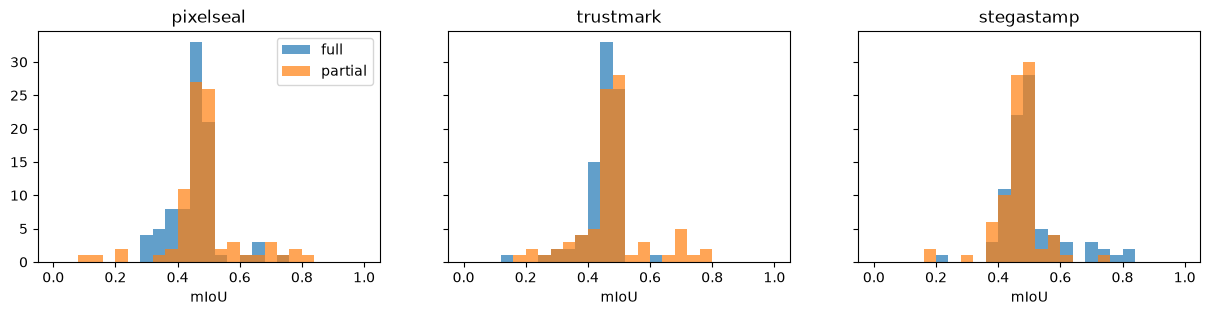

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3), sharey=True)
for ax, m in zip(axs, data.METHODS):
    c = cv[m]; f = df.loc[c['names'].tolist()].full_watermark.values
    ax.hist(c['miou'][f], bins=np.linspace(0, 1, 26), alpha=.7, label='full')
    ax.hist(c['miou'][~f], bins=np.linspace(0, 1, 26), alpha=.7, label='partial'); ax.set_title(m); ax.set_xlabel('mIoU')
axs[0].legend(); plt.show()